# Auto MPG — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [UCI Machine Learning Repository, Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) · [DOI: 10.24432/C5859H](https://doi.org/10.24432/C5859H). Original dataset credited to R. Quinlan (1993), derived from CMU StatLib. License: CC BY 4.0.

The dataset describes **398 cars** from model years 1970–1982. The response is **city-cycle fuel efficiency** in miles per gallon (`mpg`). It is an observational collection of historical cars, not a randomized experiment or a representative sample of today's vehicles.

Each row is one car.

| Column | Description |
|---|---|
| `mpg` | City-cycle fuel efficiency (miles per US gallon) |
| `cylinders` | Number of engine cylinders |
| `displacement` | Engine displacement (cubic inches) |
| `horsepower` | Engine power (hp); **6 values missing** |
| `weight` | Vehicle weight (lb) |
| `acceleration` | Acceleration measure (seconds) |
| `model_year` | Model year (70–82 means 1970–1982) |
| `origin` | Origin region code: 1 = USA, 2 = Europe, 3 = Japan (categorical, not a quantity) |
| `car_name` | Car name / model identifier (text) |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the data (internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
RAW_PATH = DATA / 'auto-mpg.data'
URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'
COLUMNS = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
           'acceleration', 'model_year', 'origin', 'car_name']

if not RAW_PATH.is_file():
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    RAW_PATH.write_bytes(r.content)

# Whitespace-separated file, car names in quotes, missing horsepower coded as '?'
df = pd.read_csv(RAW_PATH, sep=r'\s+', header=None, names=COLUMNS,
                 na_values='?', quotechar='"')
df['origin_label'] = df['origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
print(df.shape)
df.head()

(398, 10)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,origin_label
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu,USA
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320,USA
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite,USA
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst,USA
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino,USA


In [2]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mpg,398.0,NaN,NaN,NaN,23.514573,7.815984,9.0,17.5,23.0,29.0,46.6
cylinders,398.0,NaN,NaN,NaN,5.454774,1.701004,3.0,4.0,4.0,8.0,8.0
displacement,398.0,NaN,NaN,NaN,193.425879,104.269838,68.0,104.25,148.5,262.0,455.0
horsepower,392.0,NaN,NaN,NaN,104.469388,38.49116,46.0,75.0,93.5,126.0,230.0
weight,398.0,NaN,NaN,NaN,2970.424623,846.841774,1613.0,2223.75,2803.5,3608.0,5140.0
acceleration,398.0,NaN,NaN,NaN,15.56809,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,NaN,NaN,NaN,76.01005,3.697627,70.0,73.0,76.0,79.0,82.0
origin,398.0,NaN,NaN,NaN,1.572864,0.802055,1.0,1.0,1.0,2.0,3.0
car_name,398,305,ford pinto,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_label,398,3,USA,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
origin_label    0
dtype: int64

## 2. A first look

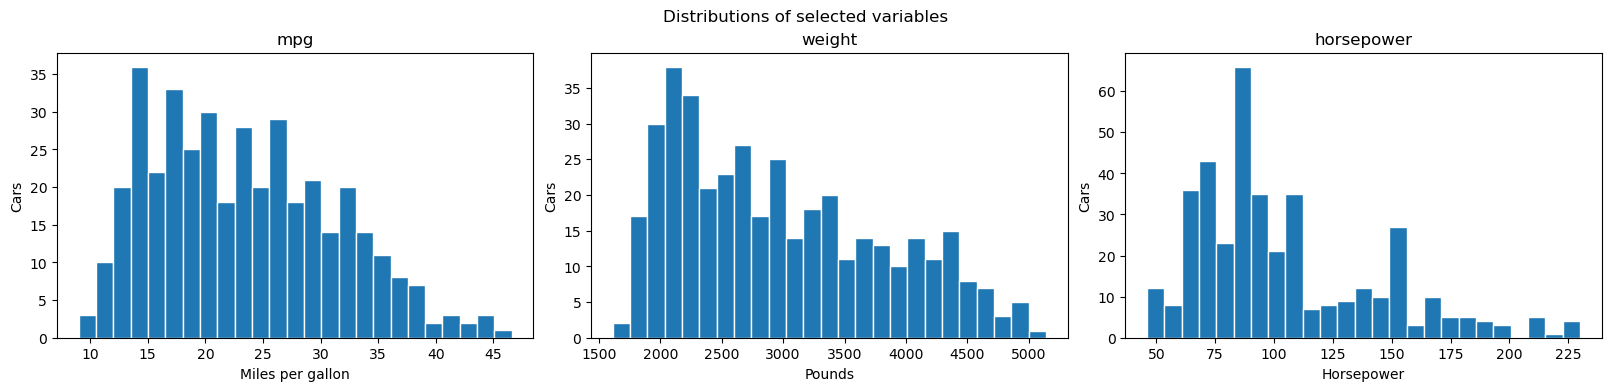

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), constrained_layout=True)
for ax, col, xlabel in zip(axs, ['mpg', 'weight', 'horsepower'],
                           ['Miles per gallon', 'Pounds', 'Horsepower']):
    ax.hist(df[col].dropna(), bins=25, edgecolor='white')
    ax.set(xlabel=xlabel, ylabel='Cars', title=col)
fig.suptitle('Distributions of selected variables')
plt.show()

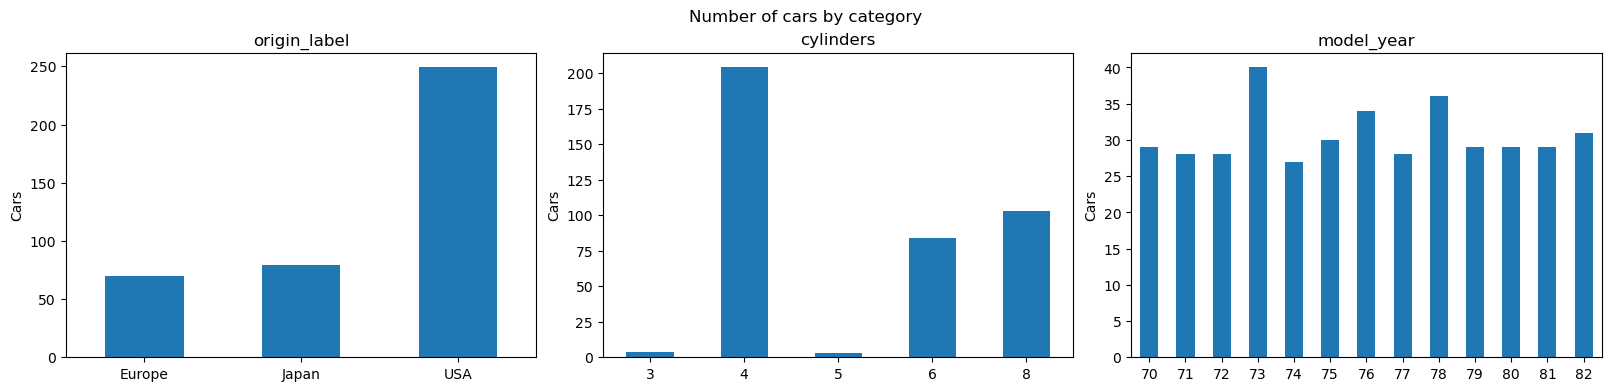

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), constrained_layout=True)
for ax, col in zip(axs, ['origin_label', 'cylinders', 'model_year']):
    df[col].value_counts().sort_index().plot.bar(ax=ax, rot=0)
    ax.set(xlabel='', ylabel='Cars', title=col)
fig.suptitle('Number of cars by category')
plt.show()

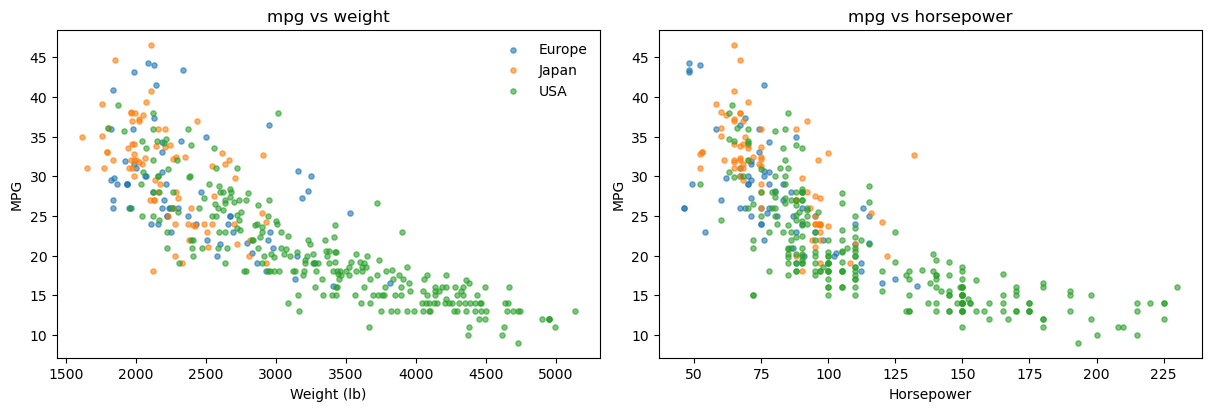

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, col, xlabel in zip(axs, ['weight', 'horsepower'], ['Weight (lb)', 'Horsepower']):
    for label, g in df.groupby('origin_label'):
        ax.scatter(g[col], g['mpg'], s=14, alpha=0.6, label=label)
    ax.set(xlabel=xlabel, ylabel='MPG', title=f'mpg vs {col}')
axs[0].legend(frameon=False)
plt.show()

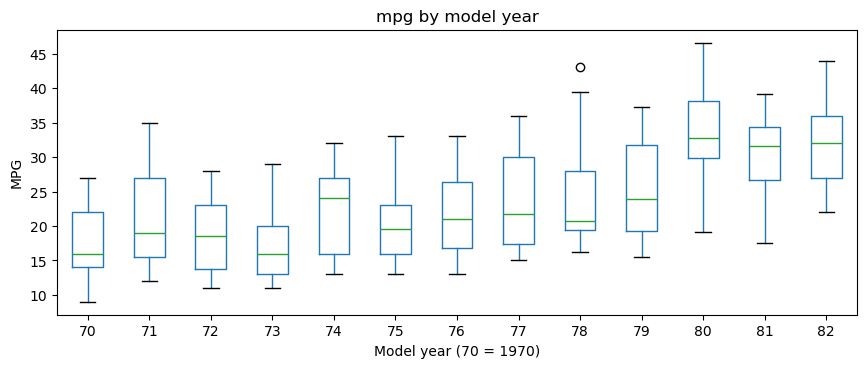

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
df.boxplot(column='mpg', by='model_year', ax=ax, grid=False)
ax.set(xlabel='Model year (70 = 1970)', ylabel='MPG', title='mpg by model year')
fig.suptitle('')
plt.show()

## 3. Your exploration
Add your own analysis below.